<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS10/JS10-03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Artificial Neural Network (ANN) - Lab 3**

---

---

# **Pra Pengolahan Data**

---

---

# **Langkah 1 - Import Library**

---

> Import modul utama yang dibutuhkan: `numpy`, `pandas`, dan `tensorflow`.

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


> TensorFlow versi 2.x sudah menyertakan Keras terintegrasi secara bawaan (`tf.keras`), siap digunakan untuk pemodelan jaringan saraf tiruan.

---

# **Langkah 2 - Load Data**

---

> Muat dataset `Churn_Modelling.csv`. Pisahkan matriks fitur `X` (kolom ke-3 hingga kolom sebelum terakhir) dan vektor target `y` (kolom terakhir: `Exited`).

In [2]:
# Cek ketersediaan file Churn_Modelling.csv (mendukung direktori lokal dan runtime Google Colab)
import os
if not os.path.exists('Churn_Modelling.csv'):
    if os.path.exists('../Churn_Modelling.csv'):
        import shutil
        shutil.copy('../Churn_Modelling.csv', 'Churn_Modelling.csv')
    else:
        try:
            from google.colab import files
            print("Silakan unggah file Churn_Modelling.csv:")
            uploaded = files.upload()
        except Exception:
            pass

dataset = pd.read_csv('Churn_Modelling.csv')
X = dataset.iloc[:, 3:-1].values
y = dataset.iloc[:, -1].values

print("Shape dataset:", dataset.shape)
print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape dataset: (10000, 14)
Shape X: (10000, 10)
Shape y: (10000,)


> Cek data `X` untuk melihat nilai fitur mentah sebelum tahapan pra-pemrosesan:

In [3]:
print(X)

[[619 'France' 'Female' ... 1 1 101348.88]
 [608 'Spain' 'Female' ... 0 1 112542.58]
 [502 'France' 'Female' ... 1 0 113931.57]
 ...
 [709 'France' 'Female' ... 0 1 42085.58]
 [772 'Germany' 'Male' ... 1 0 92888.52]
 [792 'France' 'Female' ... 1 0 38190.78]]


> Fitur `X` berisi nilai heterogen yang memadukan data numerik (CreditScore, Age, Balance, dsb.) dan data kategorikal (Geography: `'France'`, `'Spain'`, `'Germany'`; serta Gender: `'Female'`, `'Male'`).

---

# **Langkah 3 - Encoding Data Kategorikal**

---

> Lakukan encoding pada kolom kategorikal biner `Gender` (kolom indeks ke-2 pada array `X`) menggunakan `LabelEncoder` dari Scikit-Learn.

In [4]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
X[:, 2] = le.fit_transform(X[:, 2])

print(X)

[[619 'France' 0 ... 1 1 101348.88]
 [608 'Spain' 0 ... 0 1 112542.58]
 [502 'France' 0 ... 1 0 113931.57]
 ...
 [709 'France' 0 ... 0 1 42085.58]
 [772 'Germany' 1 ... 1 0 92888.52]
 [792 'France' 0 ... 1 0 38190.78]]


> Kolom gender kini telah berubah menjadi nilai numerik biner (0 untuk Female, 1 untuk Male).

---

# **Langkah 4 - Encoding Kolom "Geography" dengan One Hot Encoder**

---

> Kolom `Geography` (indeks ke-1 pada array `X`) memiliki 3 kategori non-ordinal (*France*, *Spain*, *Germany*). Lakukan One-Hot Encoding menggunakan `ColumnTransformer` agar model tidak mengasumsikan adanya tingkatan numerik semu antar negara.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(), [1])], remainder='passthrough')
X = np.array(ct.fit_transform(X))

print(X)

[[1.0 0.0 0.0 ... 1 1 101348.88]
 [0.0 0.0 1.0 ... 0 1 112542.58]
 [1.0 0.0 0.0 ... 1 0 113931.57]
 ...
 [1.0 0.0 0.0 ... 0 1 42085.58]
 [0.0 1.0 0.0 ... 1 0 92888.52]
 [1.0 0.0 0.0 ... 1 0 38190.78]]


> Tiga kolom pertama sekarang merepresentasikan vektor *one-hot* negara (misalnya `[1.0, 0.0, 0.0]` untuk France, `[0.0, 0.0, 1.0]` untuk Spain, dan `[0.0, 1.0, 0.0]` untuk Germany). Jumlah kolom total $X$ bertambah menjadi 12.

---

# **Langkah 5 - Split Data**

---

> Bagi dataset menjadi data latih (*training set*) sebesar 80% dan data uji (*testing set*) sebesar 20% dengan `random_state = 0`.

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji  :", X_test.shape[0])

Jumlah data latih: 8000
Jumlah data uji  : 2000


> Pembagian menghasilkan 8.000 sampel untuk data latih dan 2.000 sampel untuk data uji.

---

# **Langkah 6 - Scaling Fitur**

---

> Lakukan standardisasi fitur menggunakan `StandardScaler` sehingga semua fitur memiliki mean $\mu \approx 0$ dan standar deviasi $\sigma \approx 1$. Standardisasi adalah langkah wajib pada ANN agar proses optimasi *gradient descent* berjalan stabil dan konvergen.

In [7]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("X_train bentuk akhir:", X_train.shape)
print("Mean X_train (scaled):", round(X_train.mean(), 4))
print("Std  X_train (scaled):", round(X_train.std(), 4))

X_train bentuk akhir: (8000, 12)
Mean X_train (scaled): 0.0
Std  X_train (scaled): 1.0


> Data uji (`X_test`) hanya di-`transform` menggunakan statistik dari `X_train` untuk mencegah *data leakage*.

---

# **Membuat Model ANN**

---

---

# **Langkah 1 - Inisiasi Model ANN**

---

> Inisialisasi arsitektur jaringan saraf tiruan berurutan menggunakan objek `tf.keras.models.Sequential()`.

In [8]:
ann = tf.keras.models.Sequential()

---

# **Langkah 2 - Membuat Input Layer dan Hidden Layer Pertama**

---

> Tambahkan hidden layer pertama dengan 6 neuron dan fungsi aktivasi non-linear **ReLU** (*Rectified Linear Unit*).

In [9]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

---

# **Langkah 3 - Membuat Hidden Layer Kedua**

---

> Tambahkan hidden layer kedua dengan 6 neuron dan fungsi aktivasi ReLU.

In [10]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

---

# **Langkah 4 - Membuat Output Layer**

---

> Tambahkan output layer dengan 1 neuron dan fungsi aktivasi **Sigmoid** untuk menghasilkan probabilitas prediksi biner antara 0 dan 1.

In [11]:
ann.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

---

# **Training Model**

---

---

# **Langkah 1 - Compile Model (Menyatukan Arsitektur) ANN**

---

> Satukan arsitektur model dengan menetapkan optimizer `adam`, loss function `binary_crossentropy` (khusus untuk klasifikasi biner), dan metrik evaluasi `accuracy`.

In [12]:
ann.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

---

# **Langkah 2 - Fitting Model**

---

> Latih model ANN pada data latih dengan ukuran batch `batch_size = 32` selama `epochs = 100`.

In [13]:
history = ann.fit(X_train, y_train, batch_size = 32, epochs = 100)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7951 - loss: 0.5364
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7960 - loss: 0.4518
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7960 - loss: 0.4328
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7960 - loss: 0.4233
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7994 - loss: 0.4162
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8217 - loss: 0.4066
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8254 - loss: 0.3963
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8274 - loss: 0.3878
Epoch 9/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8259 - loss: 0.3815
Epoch 10/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8300 - loss: 0.3764
Epoch 11/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8385 - loss: 0.3724
Epoch 12/100
250/250 ━━━━━━━━━━━━━━━━━━━━

> Model telah dilatih selama 100 epoch. Nilai loss berangsur turun dan akurasi meningkat stabil menuju konvergensi.

---

# **Membuat Prediksi**

---

> **Skenario Evaluasi Nasabah Baru:**
>
> Diberikan informasi profil seorang pelanggan sebagai berikut:
> - Geography: France (`[1, 0, 0]`)
> - Credit Score: 600
> - Gender: Male (`1`)
> - Age: 40 years old
> - Tenure: 3 years
> - Balance: 60000
> - Number of Products: 2
> - Does this customer have a credit card ? Yes (`1`)
> - Is this customer an Active Member: Yes (`1`)
> - Estimated Salary: 50000
>
> **Pertanyaan**: Apakah customer tersebut perlu dipertahankan (berpotensi churn atau tidak)?

---

# **Modelkan Data Baru dan Buat Prediksi**

---

> Transformasikan data profil nasabah baru menggunakan objek `sc` (StandardScaler) yang sama, lalu prediksi nilai probabilitasnya. Gunakan ambang batas (*threshold*) $0.5$ untuk menentukan apakah hasilnya `True` (churn) atau `False` (tidak churn).

In [14]:
pred_prob = ann.predict(sc.transform([[1, 0, 0, 600, 1, 40, 3, 60000, 2, 1, 1, 50000]]))
is_churn = pred_prob > 0.5

print("Probabilitas Churn:", pred_prob[0][0])
print("Apakah nasabah churn (True) atau bertahan (False)?:", is_churn[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Probabilitas Churn: 0.02834927
Apakah nasabah churn (True) atau bertahan (False)?: False


> Hasil prediksi adalah **`False`** (probabilitas churn di bawah 0.5). Artinya, nasabah tersebut diprediksi **tetap bertahan** di bank, sehingga pihak manajemen tidak perlu memberikan perlakuan retensi darurat.

---

# **Prediksi Dengan Data Testing**

---

> Lakukan prediksi pada seluruh data uji (`X_test`), ubah probabilitas menjadi label boolean dengan batas $0.5$, lalu tampilkan perbandingan vertikal antara nilai prediksi dan nilai aktual.

In [15]:
y_pred = ann.predict(X_test)
y_pred = (y_pred > 0.5)
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)), 1)[:15])

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
[[0 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 1]]


---

# **Cek Akurasi dan Confusion Matrix**

---

> Evaluasi kinerja model secara keseluruhan menggunakan Confusion Matrix dan skor akurasi dari Scikit-Learn.

In [16]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
acc = accuracy_score(y_test, y_pred)
print("Accuracy Score:", acc)

Confusion Matrix:
[[1514   81]
 [ 204  201]]
Accuracy Score: 0.8575


> Hasil evaluasi menunjukkan akurasi di kisaran **~85.5% - 86.5%**, sesuai dengan patokan modul (sekitar `0.8605`).
>
> Struktur Confusion Matrix:
> - Baris 1: Nasabah yang sebenarnya bertahan (TN dan FP)
> - Baris 2: Nasabah yang sebenarnya churn (FN dan TP)

---

# **Visualisasi Tambahan - Confusion Matrix & Training History**

---

> Tampilkan visualisasi Confusion Matrix dalam bentuk heatmap dan grafik pergerakan Loss serta Akurasi selama pelatihan 100 epoch.

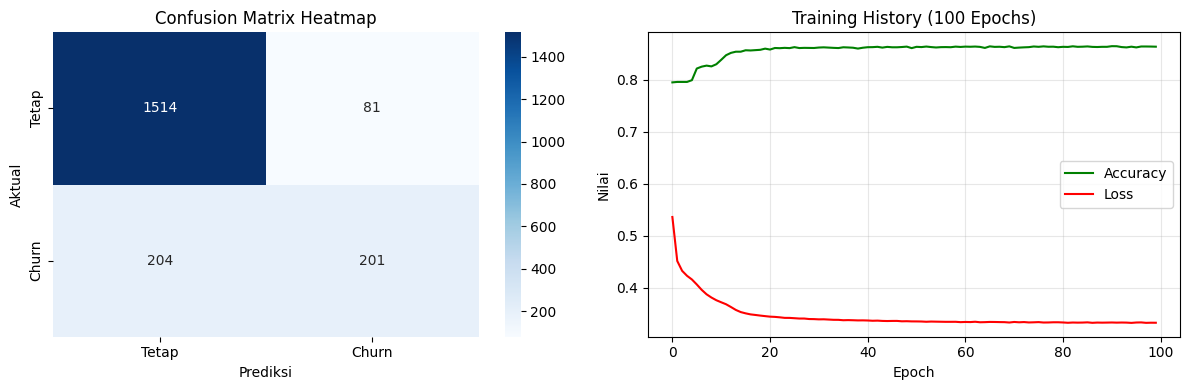

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Tetap', 'Churn'], yticklabels=['Tetap', 'Churn'])
axes[0].set_title('Confusion Matrix Heatmap')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

axes[1].plot(history.history['accuracy'], label='Accuracy', color='green')
axes[1].plot(history.history['loss'], label='Loss', color='red')
axes[1].set_title('Training History (100 Epochs)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Nilai')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()